In [1]:
# Mount Google Drive, where I saved the data
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Exercise 4: Deep Learning with Fine-Tuning
Implement and fine-tune at least two pre-trained deep learning architectures of your
choice, first on Dataset 1 and then on Dataset 2.

You are expected to carefully design:
- Data augmentation strategies
- Training procedures
- Evaluation and comparison of results

Provide the relevant Phyton code and a report in which you describe and discuss your
work. A critical part of the assessment is the discussion of your findings, especially how performance may vary depending on the dataset

### Imports

In [2]:
import numpy as np
import tensorflow_datasets as tfds
import tensorflow as tf
import matplotlib.pyplot as plt
import keras
from keras import layers
from keras.applications import EfficientNetB0, ResNet50
from keras import layers
from tensorflow import data as tf_data
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [3]:
# Drive paths to the datasets
ULTRA_DIR = "/content/drive/MyDrive/Classification_planes"
BRAIN_DIR = "/content/drive/MyDrive/brain_planes"


In [4]:
# IMG_SIZE is determined by EfficientNet model choice
IMG_SIZE = 224

# Batch size was reduced beacause of from 64 to 32 in order to lower the
# computational load and make the training process more manageable on the available hardware.
BATCH_SIZE = 32

# Number of classes present in each dataset
NUM_CLASSES = 3

In [5]:
def load_tf_dataset_splits(root_dir, img_size=IMG_SIZE, batch_size=BATCH_SIZE, seed=673):
    # 60% train, 20% val, 20% test
    train_val_ds = keras.utils.image_dataset_from_directory(
        root_dir,
        labels='inferred',
        label_mode='categorical',
        image_size=(img_size, img_size),
        batch_size=batch_size,
        shuffle=True,
        validation_split=0.4,   # 40% reserved for val+test
        subset='training',
        seed=seed,
    )

    val_ds = keras.utils.image_dataset_from_directory(
        root_dir,
        labels='inferred',
        label_mode='categorical',
        image_size=(img_size, img_size),
        batch_size=batch_size,
        shuffle=True,
        validation_split=0.4,
        subset='validation',
        seed=seed,
    )

    # Split val_ds into val + test (50/50 of that 40% = 20%+20%)
    val_batches = int(0.5 * len(val_ds))
    val_ds_final = val_ds.take(val_batches)
    test_ds = val_ds.skip(val_batches)

    return train_val_ds, val_ds_final, test_ds


In [6]:
train_ultra_ds, val_ultra_ds, test_ultra_ds = load_tf_dataset_splits(ULTRA_DIR)
train_brain_ds, val_brain_ds, test_brain_ds = load_tf_dataset_splits(BRAIN_DIR)

Found 3659 files belonging to 3 classes.
Using 2196 files for training.
Found 3659 files belonging to 3 classes.
Using 1463 files for validation.
Found 2948 files belonging to 3 classes.
Using 1769 files for training.
Found 2948 files belonging to 3 classes.
Using 1179 files for validation.


## Visualize the data

Here are the first 9 images in the training set of each dataset.

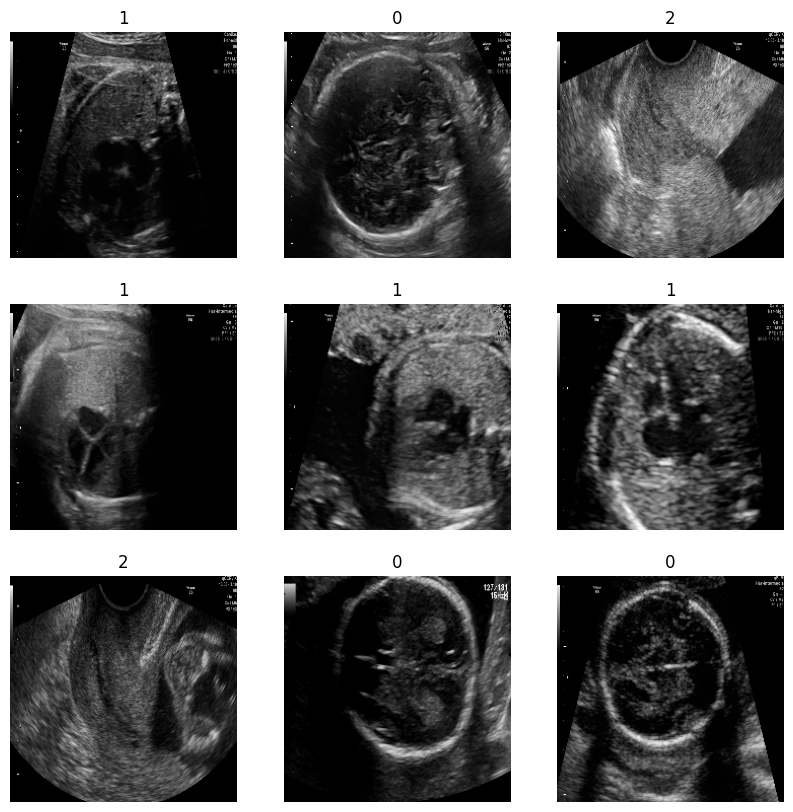

In [ ]:
plt.figure(figsize=(10, 10))
for images, labels in train_ultra_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        # Show image
        plt.imshow(np.array(images[i]).astype("uint8"))
        # Convert one‑hot vector to integer class index
        class_id = int(tf.argmax(labels[i]).numpy())
        plt.title(class_id)
        plt.axis("off")

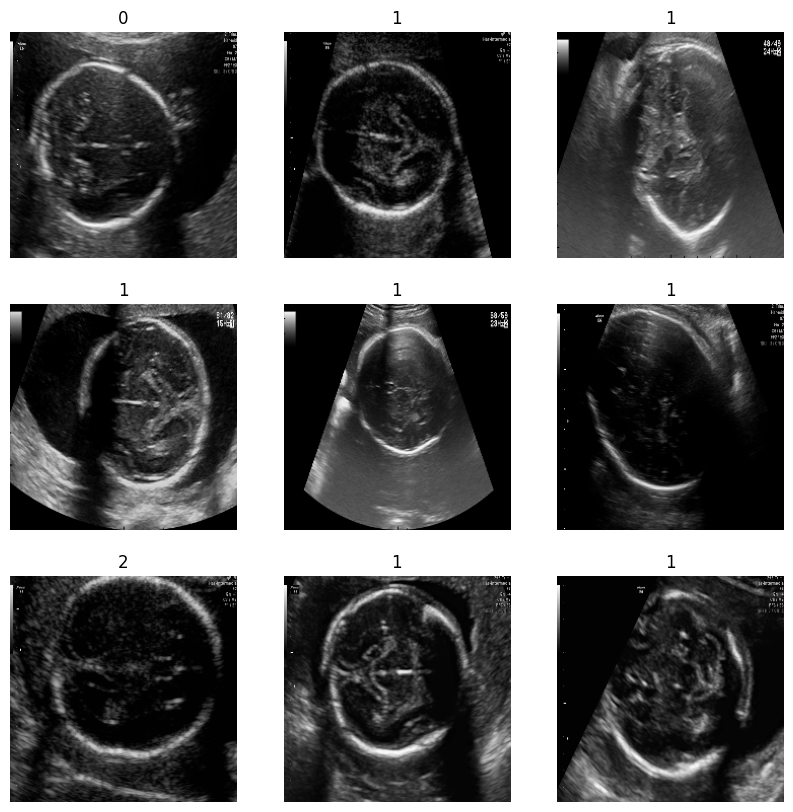

In [ ]:
plt.figure(figsize=(10, 10))
for images, labels in train_brain_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        # Show image
        plt.imshow(np.array(images[i]).astype("uint8"))
        # Convert one‑hot vector to integer class index
        class_id = int(tf.argmax(labels[i]).numpy())
        plt.title(class_id)
        plt.axis("off")


## Data augmentation

In [7]:
# Image data augmentation layers (applied only to training data)
data_augmentation_layers = [
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
]

def data_augmentation(images):
    """
    Apply a sequence of random data augmentation transforms to a batch of images.
    """
    for layer in data_augmentation_layers:
        images = layer(images)
    return images


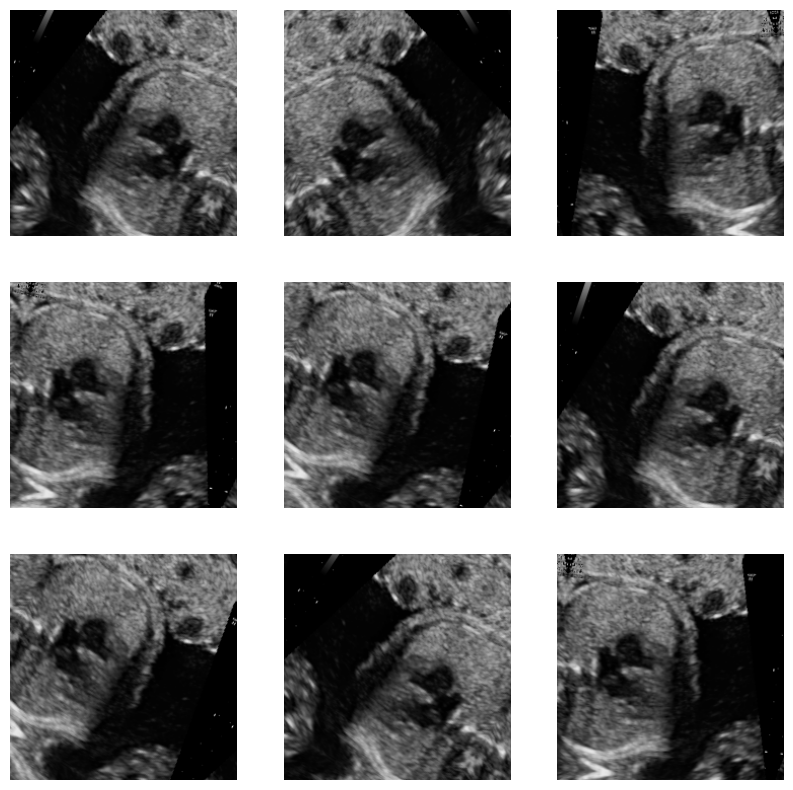

In [ ]:
# Visualization of augmented images for dataset 1
plt.figure(figsize=(10, 10))
for images, labels in train_ultra_ds.take(1):
    for i in range(9):
        augmented_images = data_augmentation(images)
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(np.array(augmented_images[0]).astype("uint8"))
        plt.axis("off")

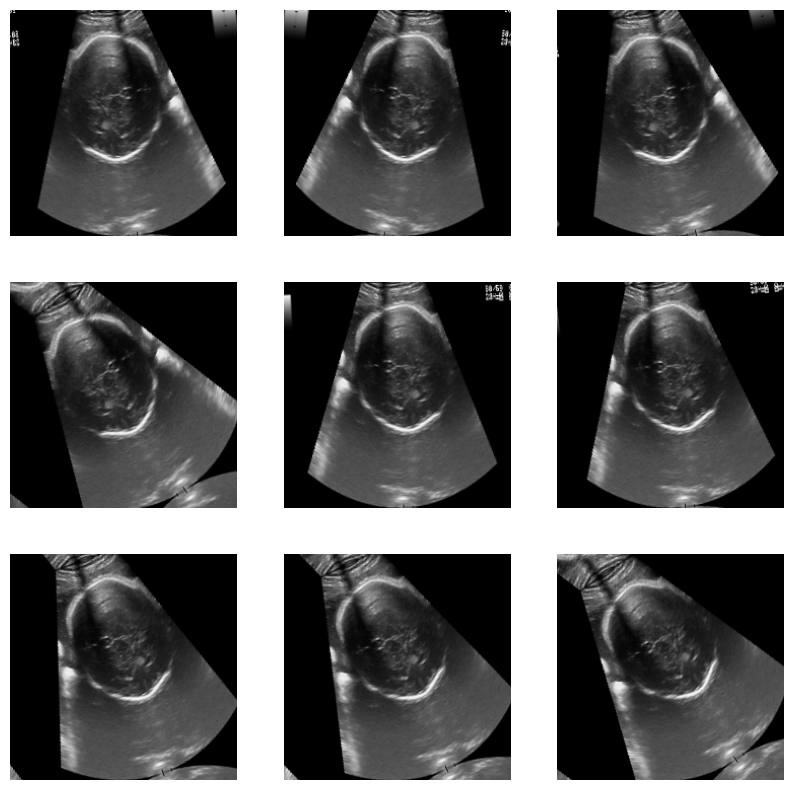

In [ ]:
# Visualization of augmented images for dataset 2
plt.figure(figsize=(10, 10))
for images, labels in train_brain_ds.take(1):
    for i in range(9):
        augmented_images = data_augmentation(images)
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(np.array(augmented_images[0]).astype("uint8"))
        plt.axis("off")


In [8]:
AUTOTUNE = tf_data.AUTOTUNE

def configure_for_training(train_ds, val_ds):
    """
    Apply data augmentation to the training dataset and add prefetching
    to both training and validation datasets.
    """
    # Apply data augmentation only on training images
    train_ds = train_ds.map(
        lambda img, label: (data_augmentation(img), label),
        num_parallel_calls=AUTOTUNE,
    )
    # Prefetch to improve pipeline performance
    train_ds = train_ds.prefetch(AUTOTUNE)
    val_ds = val_ds.prefetch(AUTOTUNE)
    return train_ds, val_ds

# Configure Dataset 1: Ultrasound
train_ultra_ds, val_ultra_ds = configure_for_training(train_ultra_ds, val_ultra_ds)

# Configure Dataset 2: Brain
train_brain_ds, val_brain_ds = configure_for_training(train_brain_ds, val_brain_ds)


## Transfer learning from pre-trained weights

Here the models with pre-trained ImageNet weights are initialized.

The models used are the following:
- EfficientNetB0
- ResNet50

### Why ResNet50

- Official documentation can be found [here](https://keras.io/api/applications/resnet/)
- the standard pre‑trained ResNet model expects RGB images with an input size of 224×224, which matches the image requirements already used for EfficientNetB0, allowing both networks to be trained on the exact same preprocessed datasets without additional resizing logic.


In [9]:
def build_effnet_model(num_classes=NUM_CLASSES):
    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    base = EfficientNetB0(
        include_top=False,
        weights="imagenet",
        input_tensor=inputs,
    )

    # Freeze the pretrained weights
    base.trainable = False

    # Rebuild top
    x = layers.GlobalAveragePooling2D(name="avg_pool")(base.output)
    x = layers.Dropout(0.2, name="top_dropout")(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="pred")(x)

    # Compile
    model = keras.Model(inputs, outputs, name="EfficientNetB0_finetune")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

def build_resnet_model(num_classes=NUM_CLASSES):
    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    base = ResNet50(
        include_top=False,
        weights="imagenet",
        input_tensor=inputs,
    )

    # Freeze the pretrained weights
    base.trainable = False

    # Rebuild top
    x = layers.GlobalAveragePooling2D(name="avg_pool")(base.output)
    x = layers.Dropout(0.3, name="top_dropout")(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="pred")(x)

    # Compile
    model = keras.Model(inputs, outputs, name="ResNet50_finetune")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


In [10]:
# Function to unfreeze last layers of the model for fine-tuning
def unfreeze_last_layers(model, n_layers=20, lr=1e-5):
    """
    Unfreeze the last `n_layers` of the model (except BatchNormalization layers)
    and recompile with a lower learning rate for fine-tuning.
    """
    # Iterate over the last n_layers of the model
    for layer in model.layers[-n_layers:]:
        # Keep BatchNormalization layers frozen for stability
        if not isinstance(layer, layers.BatchNormalization):
            layer.trainable = True

    # Recompile the model after changing trainable status
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),  # smaller LR for fine-tuning
        loss="categorical_crossentropy",
        metrics=["accuracy"],
    )

### EfficientNetB0

#### Dataset 1

In [ ]:
# =========================
# DATASET 1: ULTRASOUND
# =========================

# Build EfficientNetB0 model for ultrasound dataset
eff_ultra = build_effnet_model(NUM_CLASSES)

# Phase 1: feature extraction (only the new top layers are trainable)
EPOCHS_FE = 10
hist_eff_ultra_fe = eff_ultra.fit(
    train_ultra_ds,               # training set with data augmentation
    epochs=EPOCHS_FE,             # number of epochs for feature extraction
    validation_data=val_ultra_ds  # validation set (no augmentation was applied)
)


# Apply unfreezing to EfficientNet model for ultrasound
unfreeze_last_layers(eff_ultra, n_layers=20, lr=1e-5)

# Phase 2: fine-tuning (top + last part of EfficientNet become trainable)
EPOCHS_FT = 10
hist_eff_ultra_ft = eff_ultra.fit(
    train_ultra_ds,                # same training set, still with augmentation
    epochs=EPOCHS_FT,              # number of epochs for fine-tuning
    validation_data=val_ultra_ds,  # same validation set
)


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
69/69 ━━━━━━━━━━━━━━━━━━━━ 409s 6s/step - accuracy: 0.6845 - loss: 0.7215 - val_accuracy: 0.9633 - val_loss: 0.1544
Epoch 2/10
69/69 ━━━━━━━━━━━━━━━━━━━━ 242s 3s/step - accuracy: 0.9508 - loss: 0.1731 - val_accuracy: 0.9810 - val_loss: 0.0943
Epoch 3/10
69/69 ━━━━━━━━━━━━━━━━━━━━ 243s 4s/step - accuracy: 0.9682 - loss: 0.1303 - val_accuracy: 0.9837 - val_loss: 0.0714
Epoch 4/10
69/69 ━━━━━━━━━━━━━━━━━━━━ 249s 3s/step - accuracy: 0.9698 - loss: 0.1072 - val_accuracy: 0.9851 - val_loss: 0.0652
Epoch 5/10
69/69 ━━━━━━━━━━━━━━━━━━━━ 271s 4s/step - accuracy: 0.9824 - loss: 0.0843 - val_accuracy: 0.9905 - val_loss: 0.0488
Epoch 6/10
69/69 ━━━━━━━━━━━━━━━━━━━━ 254s 4s/step - accuracy: 0.9755 - loss: 0.0847 - val_accuracy: 0.9878 - val_loss: 0.0496
Epoch 7/10
69/69 ━━━━━━━━━━━━━━━━━━━━ 241s 3s/step - accuracy: 0.9780 - loss: 0.0786 - val_accuracy: 0.9878 - val_loss: 0.0458
Epoch 8/10
69/69 ━━━━━━━━━━━━━━━━━━━━ 248s 4s/step - accurac

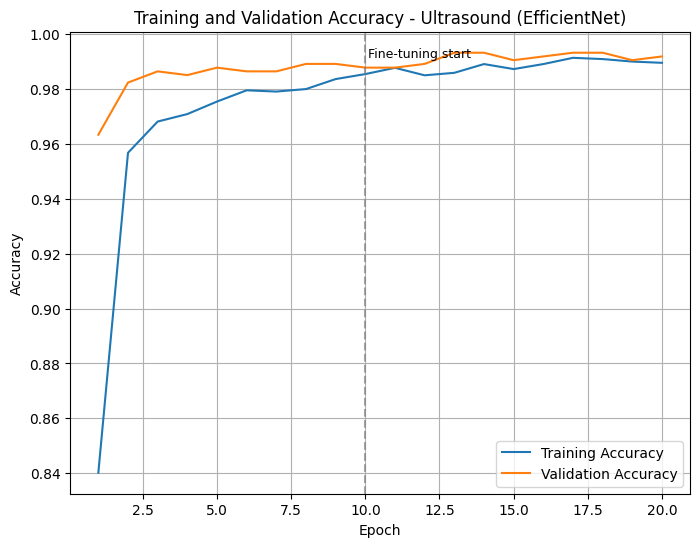

In [ ]:
# Extract metrics from both phases ---

# Phase 1 (feature extraction)
acc_fe = hist_eff_ultra_fe.history["accuracy"]
val_acc_fe = hist_eff_ultra_fe.history["val_accuracy"]

# Phase 2 (fine-tuning)
acc_ft = hist_eff_ultra_ft.history["accuracy"]
val_acc_ft = hist_eff_ultra_ft.history["val_accuracy"]

# Concatenate metrics
acc_total = acc_fe + acc_ft
val_acc_total = val_acc_fe + val_acc_ft

# Build epoch range (1..total_epochs)
epochs_total = range(1, len(acc_total) + 1)

# Plot training vs validation accuracy ---

plt.figure(figsize=(8, 6))
plt.plot(epochs_total, acc_total, label="Training Accuracy")
plt.plot(epochs_total, val_acc_total, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy - Ultrasound (EfficientNet)")
plt.legend()
plt.grid(True)

# Optional: vertical line to separate phase 1 and 2
plt.axvline(x=len(acc_fe), color="gray", linestyle="--", alpha=0.7)
plt.text(len(acc_fe) + 0.1, max(acc_total), "Fine-tuning start", fontsize=9)

plt.show()


In [ ]:
# Evaluate fine-tuned EfficientNet on test set (Ultrasound)
test_loss_ultra, test_acc_ultra = eff_ultra.evaluate(test_ultra_ds)
print("Test accuracy (Ultrasound - EfficientNet):", test_acc_ultra)

23/23 ━━━━━━━━━━━━━━━━━━━━ 161s 7s/step - accuracy: 0.9919 - loss: 0.0300
Test accuracy (Ultrasound - EfficientNet): 0.9903714060783386


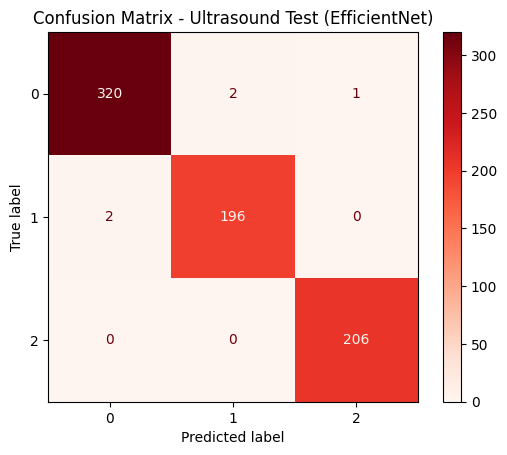

In [ ]:
# Plot of confusion matrix

# Collect true labels and predictions for test set
y_true_ultra, y_pred_ultra = [], []
for images, labels in test_ultra_ds:
    preds = eff_ultra.predict(images, verbose=0)
    y_true_ultra.extend(np.argmax(labels.numpy(), axis=1))   # from one-hot to class index
    y_pred_ultra.extend(np.argmax(preds, axis=1))

cm_ultra = confusion_matrix(y_true_ultra, y_pred_ultra)
disp_ultra = ConfusionMatrixDisplay(confusion_matrix=cm_ultra)
disp_ultra.plot(cmap="Reds")
plt.title("Confusion Matrix - Ultrasound Test (EfficientNet)")
plt.show()

#### Dataset 2

In [11]:
# =========================
# DATASET 2: BRAIN
# =========================

# Build EfficientNetB0 model for brain dataset
eff_brain = build_effnet_model(NUM_CLASSES)

# Phase 1: feature extraction on brain dataset
EPOCHS_FE = 10
hist_eff_brain_fe = eff_brain.fit(
    train_brain_ds,          # brain training set with augmentation
    epochs=EPOCHS_FE,        # reuse same number of epochs as ultrasound
    validation_data=val_brain_ds,  # brain validation set
)

# Unfreeze last layers for fine-tuning on brain dataset
unfreeze_last_layers(eff_brain, n_layers=20, lr=1e-5)

# Phase 2: fine-tuning on brain dataset
EPOCHS_FT = 10
hist_eff_brain_ft = eff_brain.fit(
    train_brain_ds,          # brain training set
    epochs=EPOCHS_FT,        # same fine-tuning epochs
    validation_data=val_brain_ds,  # brain validation set
)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 260s 4s/step - accuracy: 0.5002 - loss: 1.0575 - val_accuracy: 0.5990 - val_loss: 0.8929
Epoch 2/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 40s 713ms/step - accuracy: 0.5905 - loss: 0.9040 - val_accuracy: 0.6476 - val_loss: 0.8311
Epoch 3/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 38s 674ms/step - accuracy: 0.6408 - loss: 0.7991 - val_accuracy: 0.6875 - val_loss: 0.7831
Epoch 4/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 35s 621ms/step - accuracy: 0.6393 - loss: 0.8035 - val_accuracy: 0.6753 - val_loss: 0.7791
Epoch 5/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 37s 663ms/step - accuracy: 0.6565 - loss: 0.7963 - val_accuracy: 0.6736 - val_loss: 0.7681
Epoch 6/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 38s 669ms/step - accuracy: 0.6947 - loss: 0.7236 - val_accuracy: 0.6858 - val_loss: 0.7229
Epoch 7/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 33s 591ms/step - accuracy: 0.6739 - loss: 0.7248 - val_accuracy: 0.6910 - val_loss: 0.7393
Epoch 8/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 37s 667ms/

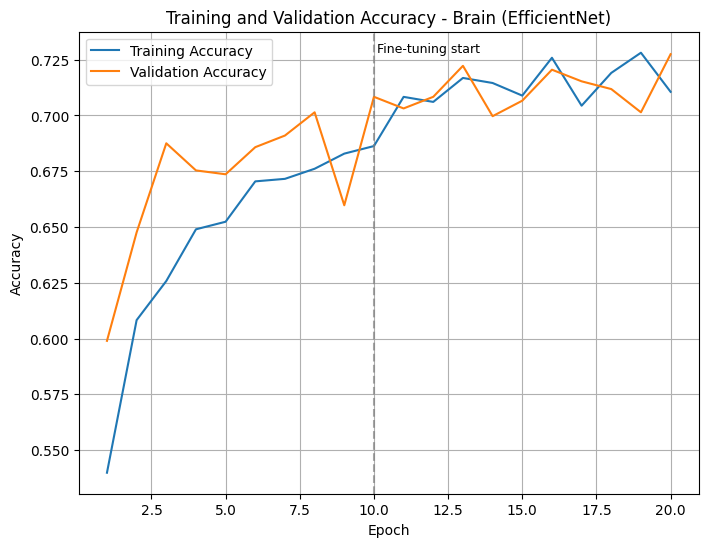

In [12]:
# Extract metrics from both phases

# Phase 1 (feature extraction)
acc_fe = hist_eff_brain_fe.history["accuracy"]
val_acc_fe = hist_eff_brain_fe.history["val_accuracy"]

# Phase 2 (fine-tuning)
acc_ft = hist_eff_brain_ft.history["accuracy"]
val_acc_ft = hist_eff_brain_ft.history["val_accuracy"]

# Concatenate metrics
acc_total = acc_fe + acc_ft
val_acc_total = val_acc_fe + val_acc_ft

# Build epoch range (1..total_epochs)
epochs_total = range(1, len(acc_total) + 1)

# Plot training vs validation accuracy ---

plt.figure(figsize=(8, 6))
plt.plot(epochs_total, acc_total, label="Training Accuracy")
plt.plot(epochs_total, val_acc_total, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy - Brain (EfficientNet)")
plt.legend()
plt.grid(True)

# Vertical line to separate phase 1 and 2
plt.axvline(x=len(acc_fe), color="gray", linestyle="--", alpha=0.7)
plt.text(len(acc_fe) + 0.1, max(acc_total), "Fine-tuning start", fontsize=9)

plt.show()


In [ ]:
# Evaluate fine-tuned EfficientNet on test set (Brain)
test_loss_brain, test_acc_brain = eff_brain.evaluate(test_brain_ds)
print("Test accuracy (Brain - EfficientNet):", test_acc_brain)


19/19 ━━━━━━━━━━━━━━━━━━━━ 89s 5s/step - accuracy: 0.7054 - loss: 0.6473
Test accuracy (Brain - EfficientNet): 0.7097843885421753


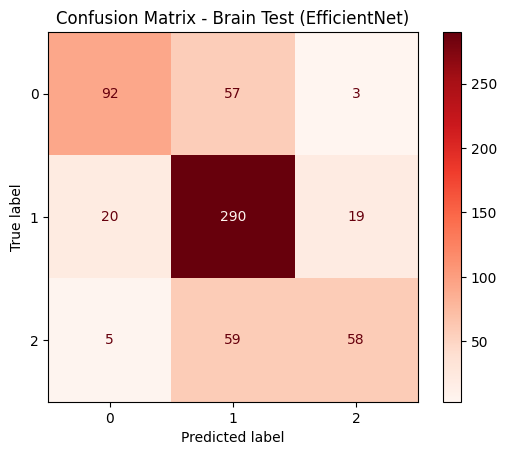

In [ ]:
# Plot of confusion matrix

# Collect true labels and predictions for test set
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_true_brain, y_pred_brain = [], []
for images, labels in test_brain_ds:
    preds = eff_brain.predict(images, verbose=0)
    y_true_brain.extend(np.argmax(labels.numpy(), axis=1))   # one-hot -> class index
    y_pred_brain.extend(np.argmax(preds, axis=1))

cm_brain = confusion_matrix(y_true_brain, y_pred_brain)
disp_brain = ConfusionMatrixDisplay(confusion_matrix=cm_brain)
disp_brain.plot(cmap="Reds")
plt.title("Confusion Matrix - Brain Test (EfficientNet)")
plt.show()

### ResNet50

#### Dataset 1

In [ ]:
# =========================
# DATASET 1: ULTRASOUND - RESNET50
# =========================

# Build ResNet50 model for ultrasound dataset
res_ultra = build_resnet_model(NUM_CLASSES)

# Phase 1: feature extraction (only the new top layers are trainable)
EPOCHS_FE = 10
hist_res_ultra_fe = res_ultra.fit(
    train_ultra_ds,              # training set with data augmentation
    epochs=EPOCHS_FE,            # number of epochs for feature extraction
    validation_data=val_ultra_ds # validation set (no augmentation was applied)
)

# Apply unfreezing to ResNet50 model for ultrasound
unfreeze_last_layers(res_ultra, n_layers=20, lr=1e-5)

# Phase 2: fine-tuning (top + last part of ResNet become trainable)
EPOCHS_FT = 10
hist_res_ultra_ft = res_ultra.fit(
    train_ultra_ds,              # same training set, still with augmentation
    epochs=EPOCHS_FT,            # number of epochs for fine-tuning
    validation_data=val_ultra_ds # same validation set
)


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/10
69/69 ━━━━━━━━━━━━━━━━━━━━ 68s 752ms/step - accuracy: 0.7048 - loss: 0.7095 - val_accuracy: 0.9755 - val_loss: 0.0805
Epoch 2/10
69/69 ━━━━━━━━━━━━━━━━━━━━ 44s 631ms/step - accuracy: 0.9302 - loss: 0.1582 - val_accuracy: 0.9864 - val_loss: 0.0480
Epoch 3/10
69/69 ━━━━━━━━━━━━━━━━━━━━ 41s 599ms/step - accuracy: 0.9575 - loss: 0.0982 - val_accuracy: 0.9851 - val_loss: 0.0409
Epoch 4/10
69/69 ━━━━━━━━━━━━━━━━━━━━ 61s 889ms/step - accuracy: 0.9679 - loss: 0.0876 - val_accuracy: 0.9891 - val_loss: 0.0400
Epoch 5/10
69/69 ━━━━━━━━━━━━━━━━━━━━ 45s 632ms/step - accuracy: 0.9763 - loss: 0.0758 - val_accuracy: 0.9810 - val_loss: 0.0551
Epoch 6/10
69/69 ━━━━━━━━━━━━━━━━━━━━ 44s 629ms/step - accuracy: 0.9775 - loss: 0.0716 - val_accuracy: 0.9878 - val_loss: 0.0402
Epoch 7/10
69/69 ━━━━━━━━━━━━━━━━━━━━ 43s 614ms/step - accuracy: 0.9729 - loss: 0.0783 - val_accuracy: 0.9905 - val_loss: 0.0336
Epoch 8/10
69/69 ━━━━━━━━━━━━━━━━━━━━ 45s 644m

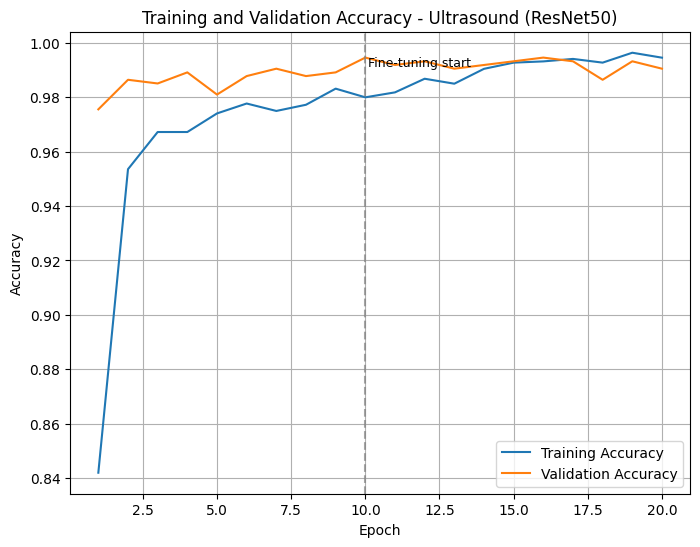

In [ ]:
#Extract metrics from both phases (ResNet50, Ultrasound)

# Phase 1 (feature extraction)
acc_fe_res = hist_res_ultra_fe.history["accuracy"]
val_acc_fe_res = hist_res_ultra_fe.history["val_accuracy"]

# Phase 2 (fine-tuning)
acc_ft_res = hist_res_ultra_ft.history["accuracy"]
val_acc_ft_res = hist_res_ultra_ft.history["val_accuracy"]

# Concatenate metrics
acc_total_res = acc_fe_res + acc_ft_res
val_acc_total_res = val_acc_fe_res + val_acc_ft_res

# Build epoch range (1..total_epochs)
epochs_total_res = range(1, len(acc_total_res) + 1)

# Plot training vs validation accuracy
plt.figure(figsize=(8, 6))
plt.plot(epochs_total_res, acc_total_res, label="Training Accuracy")
plt.plot(epochs_total_res, val_acc_total_res, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy - Ultrasound (ResNet50)")
plt.legend()
plt.grid(True)

# Vertical line to separate phase 1 and 2
plt.axvline(x=len(acc_fe), color="gray", linestyle="--", alpha=0.7)
plt.text(len(acc_fe) + 0.1, max(acc_total), "Fine-tuning start", fontsize=9)

plt.show()


In [ ]:
# Evaluate fine-tuned ResNet50 on test set (Ultrasound)
test_loss_ultra_res, test_acc_ultra_res = res_ultra.evaluate(test_ultra_ds)
print("Test accuracy (Ultrasound - ResNet50):", test_acc_ultra_res)

23/23 ━━━━━━━━━━━━━━━━━━━━ 21s 594ms/step - accuracy: 0.9819 - loss: 0.0840
Test accuracy (Ultrasound - ResNet50): 0.9876203536987305


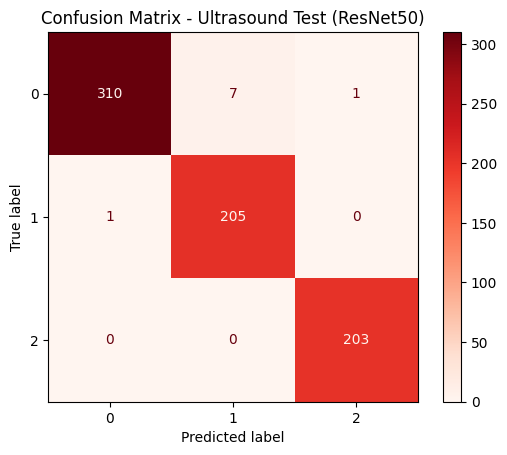

In [ ]:
# Collect true labels and predictions for test set (Ultrasound, ResNet50)
y_true_ultra_res, y_pred_ultra_res = [], []

for images, labels in test_ultra_ds:
    preds = res_ultra.predict(images, verbose=0)
    # Convert one-hot labels to class indices
    y_true_ultra_res.extend(np.argmax(labels.numpy(), axis=1))
    # Convert prediction probabilities/logits to class indices
    y_pred_ultra_res.extend(np.argmax(preds, axis=1))

# Build and plot confusion matrix
cm_ultra_res = confusion_matrix(y_true_ultra_res, y_pred_ultra_res)
disp_ultra_res = ConfusionMatrixDisplay(confusion_matrix=cm_ultra_res)
disp_ultra_res.plot(cmap="Reds")
plt.title("Confusion Matrix - Ultrasound Test (ResNet50)")
plt.show()

#### Dataset 2

In [ ]:
# =========================
# DATASET 2: BRAIN - RESNET50
# =========================

# Build ResNet50 model for brain dataset
res_brain = build_resnet_model(NUM_CLASSES)

# Phase 1: feature extraction (only the new top layers are trainable)
EPOCHS_FE = 10
hist_res_brain_fe = res_brain.fit(
    train_brain_ds,              # training set with data augmentation
    epochs=EPOCHS_FE,            # number of epochs for feature extraction
    validation_data=val_brain_ds # validation set (no augmentation was applied)
)

# Apply unfreezing to ResNet50 model for brain dataset
unfreeze_last_layers(res_brain, n_layers=20, lr=1e-5)

# Phase 2: fine-tuning (top + last part of ResNet become trainable)
EPOCHS_FT = 10
hist_res_brain_ft = res_brain.fit(
    train_brain_ds,              # same training set, still with augmentation
    epochs=EPOCHS_FT,            # number of epochs for fine-tuning
    validation_data=val_brain_ds # same validation set
)


Epoch 1/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 57s 781ms/step - accuracy: 0.4758 - loss: 1.4711 - val_accuracy: 0.5972 - val_loss: 0.9165
Epoch 2/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 40s 718ms/step - accuracy: 0.5655 - loss: 1.0952 - val_accuracy: 0.6337 - val_loss: 0.8126
Epoch 3/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 34s 605ms/step - accuracy: 0.5956 - loss: 0.9475 - val_accuracy: 0.6562 - val_loss: 0.7836
Epoch 4/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 35s 610ms/step - accuracy: 0.6172 - loss: 0.9157 - val_accuracy: 0.6667 - val_loss: 0.7866
Epoch 5/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 33s 594ms/step - accuracy: 0.6276 - loss: 0.8531 - val_accuracy: 0.6372 - val_loss: 0.9006
Epoch 6/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 35s 618ms/step - accuracy: 0.6170 - loss: 0.8942 - val_accuracy: 0.6823 - val_loss: 0.7377
Epoch 7/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 33s 595ms/step - accuracy: 0.6517 - loss: 0.8182 - val_accuracy: 0.6944 - val_loss: 0.7271
Epoch 8/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 41s 594ms/step - accuracy: 0.6551 - loss: 0.8050 - val_accu

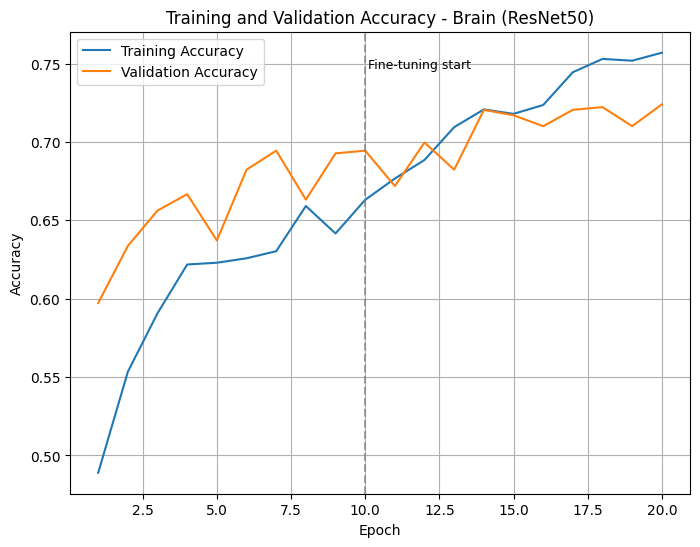

In [ ]:
# Extract metrics from both phases (ResNet50, Brain)

# Phase 1 (feature extraction)
acc_fe_res_brain = hist_res_brain_fe.history["accuracy"]
val_acc_fe_res_brain = hist_res_brain_fe.history["val_accuracy"]

# Phase 2 (fine-tuning)
acc_ft_res_brain = hist_res_brain_ft.history["accuracy"]
val_acc_ft_res_brain = hist_res_brain_ft.history["val_accuracy"]

# Concatenate metrics
acc_total_res_brain = acc_fe_res_brain + acc_ft_res_brain
val_acc_total_res_brain = val_acc_fe_res_brain + val_acc_ft_res_brain

# Build epoch range (1..total_epochs)
epochs_total_res_brain = range(1, len(acc_total_res_brain) + 1)

# Plot training vs validation accuracy
plt.figure(figsize=(8, 6))
plt.plot(epochs_total_res_brain, acc_total_res_brain, label="Training Accuracy")
plt.plot(epochs_total_res_brain, val_acc_total_res_brain, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy - Brain (ResNet50)")
plt.legend()
plt.grid(True)

# Vertical line to separate phase 1 and 2
plt.axvline(x=len(acc_fe), color="gray", linestyle="--", alpha=0.7)
y_pos = max(acc_total_res_brain) - 0.01
plt.text(len(acc_fe_res_brain) + 0.1, y_pos, "Fine-tuning start", fontsize=9)

plt.show()


In [ ]:
# Evaluate fine-tuned ResNet50 on test set (Brain)
test_loss_brain_res, test_acc_brain_res = res_brain.evaluate(test_brain_ds)
print("Test accuracy (Brain - ResNet50):", test_acc_brain_res)

19/19 ━━━━━━━━━━━━━━━━━━━━ 17s 620ms/step - accuracy: 0.7036 - loss: 0.6841
Test accuracy (Brain - ResNet50): 0.7031509280204773


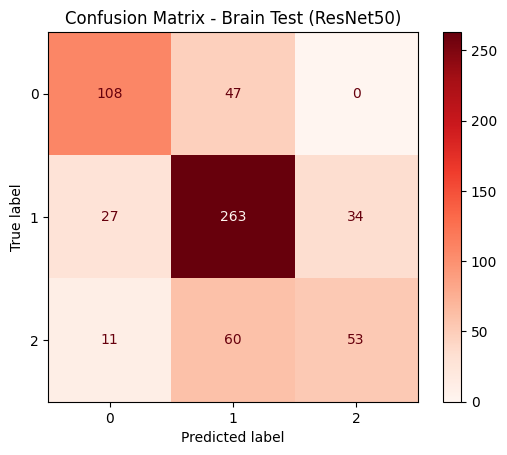

In [ ]:
# Collect true labels and predictions for test set (Brain, ResNet50)
y_true_brain_res, y_pred_brain_res = [], []

for images, labels in test_brain_ds:
    preds = res_brain.predict(images, verbose=0)
    # Convert one-hot labels to class indices
    y_true_brain_res.extend(np.argmax(labels.numpy(), axis=1))
    # Convert prediction probabilities/logits to class indices
    y_pred_brain_res.extend(np.argmax(preds, axis=1))

# Build and plot confusion matrix
cm_brain_res = confusion_matrix(y_true_brain_res, y_pred_brain_res)
disp_brain_res = ConfusionMatrixDisplay(confusion_matrix=cm_brain_res)
disp_brain_res.plot(cmap="Reds")
plt.title("Confusion Matrix - Brain Test (ResNet50)")
plt.show()
